# 10_ROCOv2_XAI

**Purpose:** Visual and textual attribution explanations — "where does each
model look, and which caption words matter" — across all three trained
models, complementing Notebook 09's latent counterfactual analysis.

### Methodology (confirmed, not assumed)
- **Scope:** all three models — DenseNet121 (05), BiomedCLIP zero-shot (06),
  Proposed VLM (07).
- **Image attribution — Grad-CAM**, architecture-appropriate target layer:
  - DenseNet121: the final convolutional feature map (`densenet.features`
    output) — the standard, textbook Grad-CAM target for a CNN.
  - BiomedCLIP (both 06 and 07's vision tower): the **last ViT transformer
    block's patch-token output**, reshaped back into its spatial patch
    grid. This is a deliberate substitution for literal attention-rollout
    (see note below) — it answers the same "which image regions drove this
    decision" question via standard, library-version-stable forward/
    backward hooks, rather than reaching into the ViT attention module's
    internal softmax computation (which varies across `timm`/`open_clip`
    versions in ways that can't be verified without the exact runtime).
    This notebook fails loudly with a clear error if the expected
    `visual.trunk.blocks` / `visual.transformer.resblocks` structure isn't
    found — it does not silently guess at internals.
- **Text attribution (Proposed VLM only)** — gradient-norm saliency per
  caption token: backprop from the target label's logit to the caption's
  token embeddings, rank tokens by gradient magnitude. Only applies to
  Notebook 07, since it's the only model where a per-sample caption is
  actual classifier input (06's zero-shot uses fixed label-name prompts,
  not per-sample captions).
- **Qualitative, not quantitative**: like typical XAI reporting in papers,
  this notebook produces illustrative case-study figures, not an aggregate
  saliency-quality metric (e.g. deletion/insertion AUC) — that would be a
  separate, explicit methodological addition not yet decided.
- All three models are loaded **read-only** — nothing is retrained.

### Inputs
- `Prepared/test_final_prepared.csv` (Notebook 08), `label_mapping.json`.
- `Prepared/Baselines/DenseNet121_Unimodal/checkpoints/densenet121_best_model.pt`
  + `densenet121_config.json` (05).
- `Prepared/Baselines/BiomedCLIP_VLM_ZeroShot/biomedclip_config.json` (06) —
  for the exact prompt template; weights are the untouched pretrained
  checkpoint.
- `Prepared/Baselines/BiomedCLIP_VLM_Trained/checkpoints/vlm_best_model.pt`
  + `vlm_config.json` (07).

### Outputs
Under `Prepared/XAI/`: per-case Grad-CAM overlay figures for all three
models, caption-token attribution figure (Proposed VLM), config,
reproducibility record, manifest.

### Non-goals
No trust score estimation (Notebook 11). No modification of any previous
notebook or model.

In [10]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import os
import io
import sys
import json
import random
import zipfile
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

XAI_DIR = PREPARED_DIR / "XAI"
FIG_DIR = XAI_DIR / "figures"
for d in [XAI_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TEST_FINAL_PREPARED_PATH = PREPARED_DIR / "test_final_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"

DENSENET_DIR = PREPARED_DIR / "Baselines" / "DenseNet121_Unimodal"
DENSENET_BEST_MODEL_PATH = DENSENET_DIR / "checkpoints" / "densenet121_best_model.pt"
DENSENET_CONFIG_PATH = DENSENET_DIR / "densenet121_config.json"

ZEROSHOT_DIR = PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_ZeroShot"
ZEROSHOT_CONFIG_PATH = ZEROSHOT_DIR / "biomedclip_config.json"

VLM_DIR = PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_Trained"
VLM_BEST_MODEL_PATH = VLM_DIR / "checkpoints" / "vlm_best_model.pt"
VLM_CONFIG_PATH = VLM_DIR / "vlm_config.json"

IMAGE_ZIP_FILES = {"test": ROCO_ROOT / "Test" / "Images" / "test_images.zip"}

CASE_STUDY_TABLE_PATH = XAI_DIR / "xai_case_studies.csv"
GRADCAM_FIGURE_PDF = FIG_DIR / "gradcam_comparison.pdf"
GRADCAM_FIGURE_PNG = FIG_DIR / "gradcam_comparison_300dpi.png"
TEXT_ATTRIBUTION_FIGURE_PDF = FIG_DIR / "caption_token_attribution.pdf"
TEXT_ATTRIBUTION_FIGURE_PNG = FIG_DIR / "caption_token_attribution_300dpi.png"
XAI_CONFIG_PATH = XAI_DIR / "xai_config.json"
REPRODUCIBILITY_PATH = XAI_DIR / "reproducibility.json"
MANIFEST_PATH = XAI_DIR / "artifact_manifest.json"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

N_CASE_STUDIES = 4
MIN_CONFIDENCE_FOR_CASE_SELECTION = 0.7

print("=" * 80)
print("NOTEBOOK 10 — XAI (GRAD-CAM + CAPTION TOKEN ATTRIBUTION)")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("XAI_DIR:", XAI_DIR)
print("Random seed:", SEED)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive available.
NOTEBOOK 10 — XAI (GRAD-CAM + CAPTION TOKEN ATTRIBUTION)
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
XAI_DIR: /content/drive/MyDrive/ROCOv2/Prepared/XAI
Random seed: 42


## 1. Verify required inputs

In [11]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "test_final_prepared.csv": TEST_FINAL_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
    "densenet121_best_model.pt": DENSENET_BEST_MODEL_PATH,
    "densenet121_config.json": DENSENET_CONFIG_PATH,
    "biomedclip_config.json (zero-shot)": ZEROSHOT_CONFIG_PATH,
    "vlm_best_model.pt": VLM_BEST_MODEL_PATH,
    "vlm_config.json": VLM_CONFIG_PATH,
}
missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 10 input artifacts are missing:\n\n" + "\n".join(missing_inputs)
        + "\n\nRun 02, 05, 06, 07, and 08 first."
    )

for name, path in IMAGE_ZIP_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Original image ZIP missing for {name}: {path}")

print("PASS — Required Notebook 02/05/06/07/08 artifacts and original image ZIPs exist.")


PASS — Required Notebook 02/05/06/07/08 artifacts and original image ZIPs exist.


## 2. Load splits and label taxonomy

In [12]:
# ============================================================
# CELL 3 — LOAD TEST-FINAL AND LABEL MAPPING
# ============================================================

test_final_df = pd.read_csv(TEST_FINAL_PREPARED_PATH)

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

assert len(label_mapping) == 18, "Authoritative label_mapping.json must contain exactly 18 labels."
LABEL_COLUMNS = [f"label_{cui}" for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
N_LABELS = len(LABEL_COLUMNS)

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

print(f"Test-final: {len(test_final_df):,} samples | {N_LABELS} labels.")


Test-final: 4,935 samples | 18 labels.


## 3. Load all three models (read-only, frozen)

DenseNet121's trained weights (05), BiomedCLIP's untouched pretrained
weights (06's zero-shot backbone), and BiomedCLIP fine-tuned + fusion head
(07). Two separate BiomedCLIP instances are needed since 06 and 07 have
different weights.

In [13]:
# ============================================================
# CELL 4 — LOAD ALL THREE MODELS
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tv_models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- DenseNet121 (05) ----
with open(DENSENET_CONFIG_PATH, "r", encoding="utf-8") as f:
    densenet_config = json.load(f)

densenet = tv_models.densenet121(weights=None)
densenet.classifier = nn.Linear(densenet.classifier.in_features, N_LABELS)
densenet_checkpoint = torch.load(DENSENET_BEST_MODEL_PATH, map_location=device)
densenet.load_state_dict(densenet_checkpoint["model_state_dict"])
densenet = densenet.to(device).eval()
for p in densenet.parameters():
    p.requires_grad = False
DENSENET_IMAGE_SIZE = densenet_config["training_config"]["image_size"]
DENSENET_CHANNEL_MEAN = None  # filled from preprocessing_config below
DENSENET_CHANNEL_STD = None

with open(PREPARED_DIR / "Preprocessing" / "preprocessing_config.json", "r", encoding="utf-8") as f:
    preprocessing_config = json.load(f)
DENSENET_CHANNEL_MEAN = preprocessing_config["image"]["channel_mean"]
DENSENET_CHANNEL_STD = preprocessing_config["image"]["channel_std"]

print(f"Loaded DenseNet121 (05): epoch={densenet_checkpoint['epoch']}, "
      f"val_macro_f1={densenet_checkpoint['validation_macro_f1']:.4f}")

# ---- BiomedCLIP backbone loader (shared code, separate instances) ----
try:
    import open_clip
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"], check=True)
    import open_clip

with open(ZEROSHOT_CONFIG_PATH, "r", encoding="utf-8") as f:
    zeroshot_config = json.load(f)
with open(VLM_CONFIG_PATH, "r", encoding="utf-8") as f:
    vlm_config = json.load(f)

BIOMEDCLIP_CHECKPOINT = vlm_config["architecture"]["backbone_checkpoint"]

def load_biomedclip():
    model, preprocess = open_clip.create_model_from_pretrained(BIOMEDCLIP_CHECKPOINT)
    tokenizer = open_clip.get_tokenizer(BIOMEDCLIP_CHECKPOINT)
    model = model.to(device).eval()
    for p in model.parameters():
        p.requires_grad = False
    return model, preprocess, tokenizer

# ---- BiomedCLIP zero-shot (06) — untouched pretrained weights ----
biomedclip_zeroshot, biomedclip_preprocess, biomedclip_tokenizer = load_biomedclip()
PROMPT_TEMPLATE = zeroshot_config.get("prompt_template", "a medical image showing {label}")

with torch.no_grad():
    prompt_texts = [PROMPT_TEMPLATE.format(label=name.lower()) for name in LABEL_NAMES]
    prompt_tokens = biomedclip_tokenizer(prompt_texts).to(device)
    prompt_embeddings = F.normalize(biomedclip_zeroshot.encode_text(prompt_tokens), dim=-1)
    zeroshot_logit_scale = biomedclip_zeroshot.logit_scale.exp().item()

print(f"Loaded BiomedCLIP zero-shot (06): prompt_template='{PROMPT_TEMPLATE}'")

# ---- Proposed VLM (07) — fine-tuned backbone + trained fusion head ----
biomedclip_vlm, _, _ = load_biomedclip()
vlm_checkpoint = torch.load(VLM_BEST_MODEL_PATH, map_location=device)
biomedclip_vlm.load_state_dict(vlm_checkpoint["backbone_state_dict"])

fusion_dim = vlm_config["training_config"]["fusion_dim"]
vlm_classifier_head = nn.Sequential(
    nn.Linear(fusion_dim, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, N_LABELS),
).to(device)
vlm_classifier_head.load_state_dict(vlm_checkpoint["head_state_dict"])
vlm_classifier_head.eval()
for p in vlm_classifier_head.parameters():
    p.requires_grad = False

print(f"Loaded Proposed VLM (07): epoch={vlm_checkpoint['epoch']}, "
      f"val_macro_f1={vlm_checkpoint['validation_macro_f1']:.4f}")
print("\nAll three models loaded read-only, eval mode, all parameters frozen. Nothing is trained here.")


Loaded DenseNet121 (05): epoch=24, val_macro_f1=0.7507
Loaded BiomedCLIP zero-shot (06): prompt_template='a medical image showing {label}'
Loaded Proposed VLM (07): epoch=12, val_macro_f1=0.8583

All three models loaded read-only, eval mode, all parameters frozen. Nothing is trained here.


## 4. Extract source ZIP to plain local files (proven pattern)

In [14]:
# ============================================================
# CELL 5 — EXTRACT TEST ZIP TO PLAIN LOCAL FILES
# ============================================================

from PIL import Image

LOCAL_IMAGE_DIR = Path("/content/rocov2_images_local")
LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
TEST_EXTRACT_DIR = LOCAL_IMAGE_DIR / "test_extracted"

def _extract_if_needed(zip_path, extract_dir, expected_members):
    extract_dir.mkdir(parents=True, exist_ok=True)
    existing = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if existing >= len(expected_members):
        print(f"Already extracted, skipping: {extract_dir} ({existing:,} files present)")
        return
    print(f"Extracting {zip_path.name} -> {extract_dir} ({len(expected_members):,} members)...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)
    extracted = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if extracted != len(expected_members):
        raise IOError(f"Extraction count mismatch: expected {len(expected_members):,}, found {extracted:,}.")
    print(f"  done: {extracted:,} files extracted.")

with zipfile.ZipFile(IMAGE_ZIP_FILES["test"], "r") as _zf:
    _members = [n for n in _zf.namelist() if not n.endswith("/")]
_extract_if_needed(IMAGE_ZIP_FILES["test"], TEST_EXTRACT_DIR, _members)

def read_test_image_bytes(member):
    return (TEST_EXTRACT_DIR / member).read_bytes()

print("PASS — local image reader ready.")


Already extracted, skipping: /content/rocov2_images_local/test_extracted (9,927 files present)
PASS — local image reader ready.


## 5. Select case studies

Fixed-seed selection from Test-final: samples the Proposed VLM predicts
confidently positive (probability > 0.7) for a label, spanning distinct
labels — chosen by an objective threshold rather than hand-picked.

In [15]:
# ============================================================
# CELL 6 — SELECT CASE STUDIES
# ============================================================

vlm_predictions_path = VLM_DIR / "vlm_predictions.csv"
vlm_preds_df = pd.read_csv(vlm_predictions_path)
vlm_preds_df["ID"] = vlm_preds_df["ID"].astype(str)
test_final_ids = set(test_final_df["ID"].astype(str))
vlm_test_final_preds = vlm_preds_df.loc[
    (vlm_preds_df["Split"] == "test") & (vlm_preds_df["ID"].isin(test_final_ids))
].copy()

rng = np.random.RandomState(SEED)
candidate_rows = []
for col, name in zip(LABEL_COLUMNS, LABEL_NAMES):
    prob_col = f"{col}_prob"
    confident = vlm_test_final_preds.loc[vlm_test_final_preds[prob_col] > MIN_CONFIDENCE_FOR_CASE_SELECTION]
    if len(confident):
        candidate_rows.append({"ID": confident.iloc[0]["ID"], "Label_Name": name,
                                "Prob": confident.iloc[0][prob_col]})

candidates_df = pd.DataFrame(candidate_rows)
if len(candidates_df) < N_CASE_STUDIES:
    raise RuntimeError(
        f"Only {len(candidates_df)} labels have a confident (>{MIN_CONFIDENCE_FOR_CASE_SELECTION}) "
        f"Test-final prediction — cannot select {N_CASE_STUDIES} case studies. Lower "
        "MIN_CONFIDENCE_FOR_CASE_SELECTION in Cell 1 rather than silently reducing the count."
    )

case_selection_df = candidates_df.sample(n=N_CASE_STUDIES, random_state=SEED).reset_index(drop=True)
case_selection_df = case_selection_df.merge(
    test_final_df[["ID", "Image_Member", "Caption"]], on="ID", how="left"
)
display(case_selection_df)


,ID,Label_Name,Prob,Image_Member,Caption
0,ROCOv2_2023_test_000152,Abdomen,1.000,test/ROCOv2_2023_test_000152.jpg,Abdominal CT.Red arrow pointing at the 9-cm re...
1,ROCOv2_2023_test_000003,Angiogram,1.000,test/ROCOv2_2023_test_000003.jpg,Digitally subtracted angiogram demonstrates ac...
2,ROCOv2_2023_test_000061,Pelvis,0.881,test/ROCOv2_2023_test_000061.jpg,Follow-up radiograph 2 years postoperatively
3,ROCOv2_2023_test_000039,Postero-Anterior,1.000,test/ROCOv2_2023_test_000039.jpg,Post-Pleurodesis Chest X-ray.


In [29]:
"""
ADDITIVE cell for Notebook 10 -- run this in a NEW cell placed AFTER the notebook's
existing case-selection cell (the one that builds the original `case_selection_df`,
N_CASE_STUDIES=4, MIN_CONFIDENCE_FOR_CASE_SELECTION=0.7). Do NOT change Cell 1's
N_CASE_STUDIES / MIN_CONFIDENCE_FOR_CASE_SELECTION values, and do NOT replace the
existing case-selection cell -- `case_selection_df` is a shared global also used by
the qualitative Grad-CAM comparison figure, the caption token-attribution figure, and
`xai_case_studies.csv` (via `case_studies_export`), all of which your manuscript's
Section 5.7.1 already discusses for the original 4 cases (including naming the Pelvis
case specifically). Reusing/overwriting it would silently regenerate those artifacts
at n=30 (an unreadable figure) and hard-fail on ALLOW_OVERWRITE=False for the CSV.

This cell instead builds a SEPARATE dataframe, `faithfulness_case_selection_df`, for
Task 5's quantitative faithfulness check only. It reuses `vlm_test_final_preds` and
`test_final_df`, which already exist in the session from the original case-selection
cell -- nothing upstream needs to change.

WHY a bigger, stratified sample: the original 4-case selection takes one candidate per
label with prob > 0.7 and no upper bound, so most candidates sit at the sigmoid
ceiling (Prob ~1.0) -- 3 of the 4 existing faithfulness results are uninformative for
exactly this reason (Q1_Revision/Q1_revision_audit.md Section 9). This version pools
ALL eligible predictions per label across 3 confidence bands and samples evenly across
them.

After running this cell, call (task5_faithfulness_COLAB_ONLY.py needs zero changes):
  run_faithfulness_suite(cases_df=faithfulness_case_selection_df,
                          output_path=XAI_DIR / "explainability_quantitative_results_expanded.csv")
(a distinct output filename so the original n=4 result isn't overwritten either --
report both, since the n=4 result is already cited/discussed in the manuscript).
"""
N_FAITHFULNESS_CASES = 30
MIN_CONFIDENCE_FOR_FAITHFULNESS = 0.5

FAITHFULNESS_CONFIDENCE_BINS = [
    (MIN_CONFIDENCE_FOR_FAITHFULNESS, 0.7, "near-boundary"),
    (0.7, 0.9, "medium"),
    (0.9, 1.01, "high"),
]

faithfulness_candidate_rows = []
for col, name in zip(LABEL_COLUMNS, LABEL_NAMES):
    prob_col = f"{col}_prob"
    eligible = vlm_test_final_preds.loc[vlm_test_final_preds[prob_col] > MIN_CONFIDENCE_FOR_FAITHFULNESS]
    for lo, hi, bin_name in FAITHFULNESS_CONFIDENCE_BINS:
        band = eligible.loc[(eligible[prob_col] >= lo) & (eligible[prob_col] < hi)]
        for _, row in band.iterrows():
            faithfulness_candidate_rows.append({"ID": row["ID"], "Label_Name": name,
                                                 "Prob": row[prob_col], "Confidence_Bin": bin_name})

faithfulness_candidates_df = pd.DataFrame(faithfulness_candidate_rows)
if faithfulness_candidates_df.empty:
    raise RuntimeError(
        f"No Test-final predictions found above MIN_CONFIDENCE_FOR_FAITHFULNESS="
        f"{MIN_CONFIDENCE_FOR_FAITHFULNESS} -- cannot select any faithfulness cases."
    )

n_per_bin = N_FAITHFULNESS_CASES // len(FAITHFULNESS_CONFIDENCE_BINS)
selected_parts = []
for _, _, bin_name in FAITHFULNESS_CONFIDENCE_BINS:
    pool = faithfulness_candidates_df.loc[faithfulness_candidates_df["Confidence_Bin"] == bin_name]
    if pool.empty:
        print(f"WARNING: confidence bin '{bin_name}' has zero eligible candidates -- skipped, "
              f"not silently padded from another bin.")
        continue
    take = min(n_per_bin, len(pool))
    selected_parts.append(pool.sample(n=take, random_state=SEED))

faithfulness_case_selection_df = pd.concat(selected_parts, ignore_index=True) if selected_parts else pd.DataFrame()
if len(faithfulness_case_selection_df) < N_FAITHFULNESS_CASES:
    print(f"NOTE: selected {len(faithfulness_case_selection_df)} cases, short of the requested "
          f"{N_FAITHFULNESS_CASES} -- one or more confidence bins had fewer eligible candidates "
          f"than n_per_bin={n_per_bin}. Reported honestly, not padded.")

faithfulness_case_selection_df = faithfulness_case_selection_df.merge(
    test_final_df[["ID", "Image_Member", "Caption"]], on="ID", how="left"
)
print(faithfulness_case_selection_df["Confidence_Bin"].value_counts())
display(faithfulness_case_selection_df)


Confidence_Bin
near-boundary    10
medium           10
high             10
Name: count, dtype: int64


,ID,Label_Name,Prob,Confidence_Bin,Image_Member,Caption
0,ROCOv2_2023_test_002404,Chest,0.6190,near-boundary,test/ROCOv2_2023_test_002404.jpg,Esophageal gap study performed on day of life ...
1,ROCOv2_2023_test_009765,Upper Extremity,0.6870,near-boundary,test/ROCOv2_2023_test_009765.jpg,Norgaard (ball-catcher) view.
2,ROCOv2_2023_test_005991,X-Ray Computed Tomography,0.5400,near-boundary,test/ROCOv2_2023_test_005991.jpg,FDG-PET CT showing gallbladder fossa lesion. F...
3,ROCOv2_2023_test_006287,Positron-Emission Tomography,0.5550,near-boundary,test/ROCOv2_2023_test_006287.jpg,PET scan demonstrating resolution of lesion se...
4,ROCOv2_2023_test_009833,Sagittal,0.5254,near-boundary,test/ROCOv2_2023_test_009833.jpg,Postoperative Grashey view.
5,ROCOv2_2023_test_002985,Lower Extremity,0.5527,near-boundary,test/ROCOv2_2023_test_002985.jpg,Scanogram showing supratrochanteric length dis...
6,ROCOv2_2023_test_005284,Upper Extremity,0.6860,near-boundary,test/ROCOv2_2023_test_005284.jpg,A 57-year-old male patient presenting end-stag...
7,ROCOv2_2023_test_007720,X-Ray Computed Tomography,0.5180,near-boundary,test/ROCOv2_2023_test_007720.jpg,Ultrasound biomicroscopy (UBM) of the left eye...
8,ROCOv2_2023_test_005036,Upper Extremity,0.5586,near-boundary,test/ROCOv2_2023_test_005036.jpg,Gartland type III supracondylar fracture of a ...
9,ROCOv2_2023_test_000383,Plain x-ray,0.5440,near-boundary,test/ROCOv2_2023_test_000383.jpg,Post removal of foreign body fluoroscopic imag...


## 6. Generic Grad-CAM (works for both CNN and ViT target layers)

A forward hook captures the target layer's output; `torch.autograd.grad`
computes the gradient of the target label's logit with respect to that
captured (non-leaf) activation directly — no backward hooks needed. ViT
patch tokens are reshaped into their spatial grid (CLS token dropped)
before the same weighted-sum-then-ReLU computation used for the CNN case.

In [17]:
# ============================================================
# CELL 7 — GENERIC GRAD-CAM FUNCTION
# ============================================================

def compute_grad_cam(forward_fn, target_layer, label_idx, is_vit=False, patch_grid_size=None):
    activations = {}

    def hook(module, inp, out):
        activations["value"] = out

    handle = target_layer.register_forward_hook(hook)
    try:
        logits = forward_fn()
        logit = logits.squeeze(0)[label_idx] if logits.dim() == 2 else logits[label_idx]
        act = activations["value"]
        grad = torch.autograd.grad(outputs=logit, inputs=act, retain_graph=False)[0]
    finally:
        handle.remove()

    if is_vit:
        if patch_grid_size is None:
            raise ValueError("patch_grid_size is required for ViT Grad-CAM.")
        n_expected_tokens = patch_grid_size * patch_grid_size + 1  # +1 for CLS
        if act.shape[1] != n_expected_tokens:
            raise RuntimeError(
                f"ViT token count mismatch: expected {n_expected_tokens} "
                f"(patch_grid_size={patch_grid_size}^2 + CLS), got {act.shape[1]}. "
                "The assumed patch grid size does not match this model — inspect "
                "the actual token count rather than trusting this default."
            )
        act_tokens = act[0, 1:, :]
        grad_tokens = grad[0, 1:, :]
        act_chw = act_tokens.reshape(patch_grid_size, patch_grid_size, -1).permute(2, 0, 1)
        grad_chw = grad_tokens.reshape(patch_grid_size, patch_grid_size, -1).permute(2, 0, 1)
    else:
        act_chw = act[0]
        grad_chw = grad[0]

    weights = grad_chw.mean(dim=(1, 2))
    cam = torch.relu(torch.einsum("c,chw->hw", weights, act_chw))
    cam = (cam / (cam.max() + 1e-8)).detach().cpu().numpy()
    return cam


def get_vit_target_layer(visual_model):
    # Fails loudly if the expected structure isn't found — never silently
    # guesses at internals that vary across timm/open_clip versions.
    if hasattr(visual_model, "trunk") and hasattr(visual_model.trunk, "blocks"):
        return visual_model.trunk.blocks[-1]
    if hasattr(visual_model, "transformer") and hasattr(visual_model.transformer, "resblocks"):
        return visual_model.transformer.resblocks[-1]
    raise RuntimeError(
        "Could not locate a supported ViT block structure on this model's .visual "
        "submodule for Grad-CAM hooking. Expected `.trunk.blocks` (timm-wrapped) or "
        "`.transformer.resblocks` (open_clip native) — inspect the actual loaded "
        "model structure and adjust get_vit_target_layer() rather than guessing."
    )

print("compute_grad_cam() and get_vit_target_layer() defined.")


compute_grad_cam() and get_vit_target_layer() defined.


## 7. Run Grad-CAM for all three models across the selected case studies

In [18]:
# ============================================================
# CELL 8 — RUN GRAD-CAM FOR ALL THREE MODELS
# ============================================================

import torchvision.transforms as T

densenet_transform = T.Compose([
    T.Resize((DENSENET_IMAGE_SIZE, DENSENET_IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=DENSENET_CHANNEL_MEAN, std=DENSENET_CHANNEL_STD),
])

zeroshot_vit_layer = get_vit_target_layer(biomedclip_zeroshot.visual)
vlm_vit_layer = get_vit_target_layer(biomedclip_vlm.visual)

# Derive the patch grid size from BiomedCLIP's own preprocessing resolution
# and its known patch size (16, per the checkpoint name) rather than
# hardcoding an assumed image size.
_biomedclip_image_size = biomedclip_preprocess.transforms[0].size
if isinstance(_biomedclip_image_size, (tuple, list)):
    _biomedclip_image_size = _biomedclip_image_size[0]
PATCH_SIZE = 16
PATCH_GRID_SIZE = _biomedclip_image_size // PATCH_SIZE
print(f"BiomedCLIP image size: {_biomedclip_image_size} | patch grid: {PATCH_GRID_SIZE}x{PATCH_GRID_SIZE}")

gradcam_results = []

for _, case in case_selection_df.iterrows():
    label_idx = LABEL_NAMES.index(case["Label_Name"])
    raw_bytes = read_test_image_bytes(case["Image_Member"])
    with Image.open(io.BytesIO(raw_bytes)) as img:
        pil_image = img.convert("RGB")

        # ---- DenseNet121 ----
        # requires_grad_(True) on the INPUT is what makes autograd build a
        # graph at all here — every model parameter was frozen in Cell 4
        # (requires_grad=False), so without this the forward pass produces
        # a plain tensor with no grad_fn and Grad-CAM's backward pass fails.
        densenet_input = densenet_transform(pil_image).unsqueeze(0).to(device).requires_grad_(True)
        cam_densenet = compute_grad_cam(
            lambda: densenet(densenet_input), densenet.features, label_idx, is_vit=False,
        )

        # ---- BiomedCLIP zero-shot ----
        zs_input = biomedclip_preprocess(pil_image).unsqueeze(0).to(device).requires_grad_(True)
        def zeroshot_forward(zs_input=zs_input):
            img_embed = F.normalize(biomedclip_zeroshot.encode_image(zs_input), dim=-1)
            return (img_embed @ prompt_embeddings.T) * zeroshot_logit_scale
        cam_zeroshot = compute_grad_cam(
            zeroshot_forward, zeroshot_vit_layer, label_idx, is_vit=True, patch_grid_size=PATCH_GRID_SIZE,
        )

        # ---- Proposed VLM (caption held fixed; attributing to the image only) ----
        vlm_input = biomedclip_preprocess(pil_image).unsqueeze(0).to(device).requires_grad_(True)
        with torch.no_grad():
            text_tokens = biomedclip_tokenizer([str(case["Caption"])]).to(device)
            text_embed_fixed = F.normalize(biomedclip_vlm.encode_text(text_tokens), dim=-1)
        def vlm_forward(vlm_input=vlm_input, text_embed_fixed=text_embed_fixed):
            img_embed = F.normalize(biomedclip_vlm.encode_image(vlm_input), dim=-1)
            fused = torch.cat([img_embed, text_embed_fixed], dim=-1)
            return vlm_classifier_head(fused)
        cam_vlm = compute_grad_cam(
            vlm_forward, vlm_vit_layer, label_idx, is_vit=True, patch_grid_size=PATCH_GRID_SIZE,
        )

    gradcam_results.append({
        "ID": case["ID"], "Label_Name": case["Label_Name"], "Caption": case["Caption"],
        "Image_Member": case["Image_Member"], "pil_image": pil_image,
        "cam_densenet": cam_densenet, "cam_zeroshot": cam_zeroshot, "cam_vlm": cam_vlm,
    })

print(f"Computed Grad-CAM for {len(gradcam_results)} case studies x 3 models.")


BiomedCLIP image size: 224 | patch grid: 14x14
Computed Grad-CAM for 4 case studies x 3 models.


## 8. Publication-quality Grad-CAM comparison figure

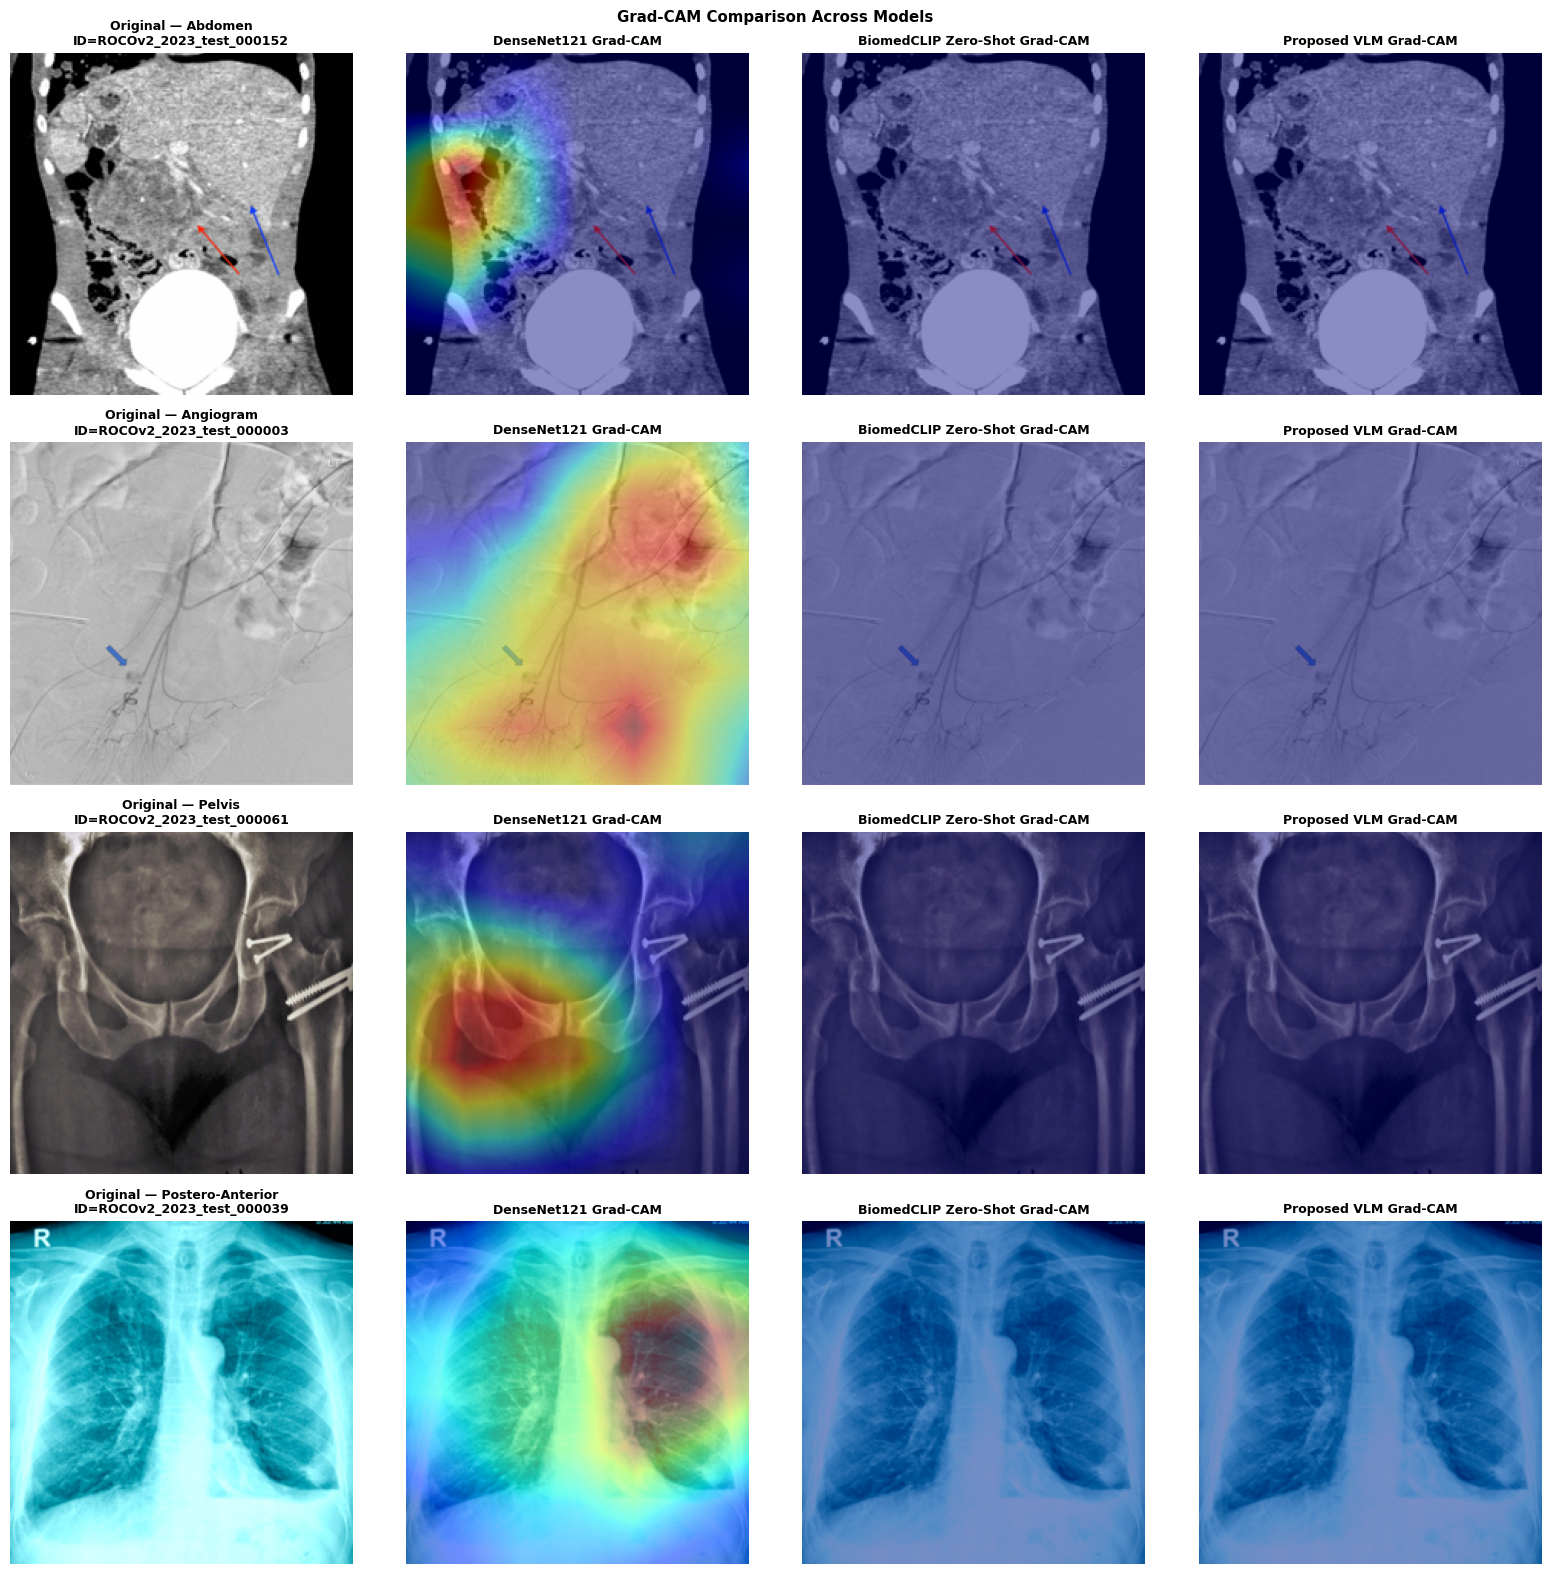

Saved: /content/drive/MyDrive/ROCOv2/Prepared/XAI/figures/gradcam_comparison.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/XAI/figures/gradcam_comparison_300dpi.png


In [19]:
# ============================================================
# CELL 9 — GRAD-CAM COMPARISON FIGURE
# ============================================================

import matplotlib.pyplot as plt
from scipy.ndimage import zoom

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 9,
})

def overlay_cam(ax, pil_image, cam, title):
    img_arr = np.array(pil_image.resize((224, 224)))
    zoom_factors = (224 / cam.shape[0], 224 / cam.shape[1])
    cam_resized = zoom(cam, zoom_factors, order=1)
    ax.imshow(img_arr)
    ax.imshow(cam_resized, cmap="jet", alpha=0.45)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

n_cases = len(gradcam_results)
fig, axes = plt.subplots(n_cases, 4, figsize=(16, 4 * n_cases))
if n_cases == 1:
    axes = axes.reshape(1, 4)

for row_i, result in enumerate(gradcam_results):
    img_arr = np.array(result["pil_image"].resize((224, 224)))
    axes[row_i, 0].imshow(img_arr)
    axes[row_i, 0].set_title(f"Original — {result['Label_Name']}\nID={result['ID']}", fontsize=9)
    axes[row_i, 0].axis("off")

    overlay_cam(axes[row_i, 1], result["pil_image"], result["cam_densenet"], "DenseNet121 Grad-CAM")
    overlay_cam(axes[row_i, 2], result["pil_image"], result["cam_zeroshot"], "BiomedCLIP Zero-Shot Grad-CAM")
    overlay_cam(axes[row_i, 3], result["pil_image"], result["cam_vlm"], "Proposed VLM Grad-CAM")

fig.suptitle("Grad-CAM Comparison Across Models", fontweight="bold")
fig.tight_layout()
fig.savefig(GRADCAM_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(GRADCAM_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", GRADCAM_FIGURE_PDF)
print("Saved:", GRADCAM_FIGURE_PNG)


## 9. Caption token attribution (Proposed VLM only)

Gradient-norm saliency: backprop from the target label's logit to the
caption's token embeddings (captured via a forward hook on the text
tower's embedding layer, since it's an intermediate tensor, not a leaf —
`retain_grad()` makes its `.grad` available after backward).

In [20]:
# ============================================================
# CELL 10 — CAPTION TOKEN ATTRIBUTION (PROPOSED VLM)
# ============================================================

def get_text_embedding_layer(text_model):
    if hasattr(text_model, "transformer") and hasattr(text_model.transformer, "embeddings"):
        return text_model.transformer.embeddings.word_embeddings
    raise RuntimeError(
        "Could not locate a supported text embedding layer on this model's .text "
        "submodule (expected `.transformer.embeddings.word_embeddings`, standard "
        "for HF BERT-family models). Inspect the actual loaded model structure "
        "rather than guessing."
    )

text_embedding_layer = get_text_embedding_layer(biomedclip_vlm.text)

def compute_caption_token_attribution(image_pil, caption, label_idx):
    captured = {}

    def hook(module, inp, out):
        # requires_grad_(True), not retain_grad(): with every biomedclip_vlm
        # parameter frozen (Cell 4), the embedding lookup's output has no
        # grad_fn to begin with (nothing upstream requires grad), so
        # retain_grad() alone would have nothing to preserve. Forcing this
        # tensor to require grad makes it the graph's effective leaf from
        # this point forward — the standard "gradient x input" embedding-
        # saliency technique.
        out.requires_grad_(True)
        captured["embeddings"] = out

    handle = text_embedding_layer.register_forward_hook(hook)
    try:
        img_input = biomedclip_preprocess(image_pil).unsqueeze(0).to(device)
        text_tokens = biomedclip_tokenizer([caption]).to(device)

        with torch.no_grad():
            img_embed_fixed = F.normalize(biomedclip_vlm.encode_image(img_input), dim=-1)

        text_embed = F.normalize(biomedclip_vlm.encode_text(text_tokens), dim=-1)
        fused = torch.cat([img_embed_fixed, text_embed], dim=-1)
        logit = vlm_classifier_head(fused)[0, label_idx]
        logit.backward()

        token_grads = captured["embeddings"].grad[0]  # [seq_len, D]
        saliency = token_grads.norm(dim=-1).detach().cpu().numpy()
    finally:
        handle.remove()

    token_ids = text_tokens[0].detach().cpu().tolist()
    tokenizer_obj = biomedclip_tokenizer.tokenizer if hasattr(biomedclip_tokenizer, "tokenizer") else None
    if tokenizer_obj is not None and hasattr(tokenizer_obj, "convert_ids_to_tokens"):
        tokens = tokenizer_obj.convert_ids_to_tokens(token_ids)
    else:
        tokens = [str(t) for t in token_ids]

    return tokens, saliency

text_attribution_results = []
for _, case in case_selection_df.iterrows():
    label_idx = LABEL_NAMES.index(case["Label_Name"])
    raw_bytes = read_test_image_bytes(case["Image_Member"])
    with Image.open(io.BytesIO(raw_bytes)) as img:
        tokens, saliency = compute_caption_token_attribution(img.convert("RGB"), str(case["Caption"]), label_idx)
    text_attribution_results.append({
        "ID": case["ID"], "Label_Name": case["Label_Name"], "tokens": tokens, "saliency": saliency,
    })

print(f"Computed caption token attribution for {len(text_attribution_results)} case studies.")


Computed caption token attribution for 4 case studies.


In [22]:
ALLOW_OVERWRITE=True

## 10. Publication-quality caption-token attribution figure

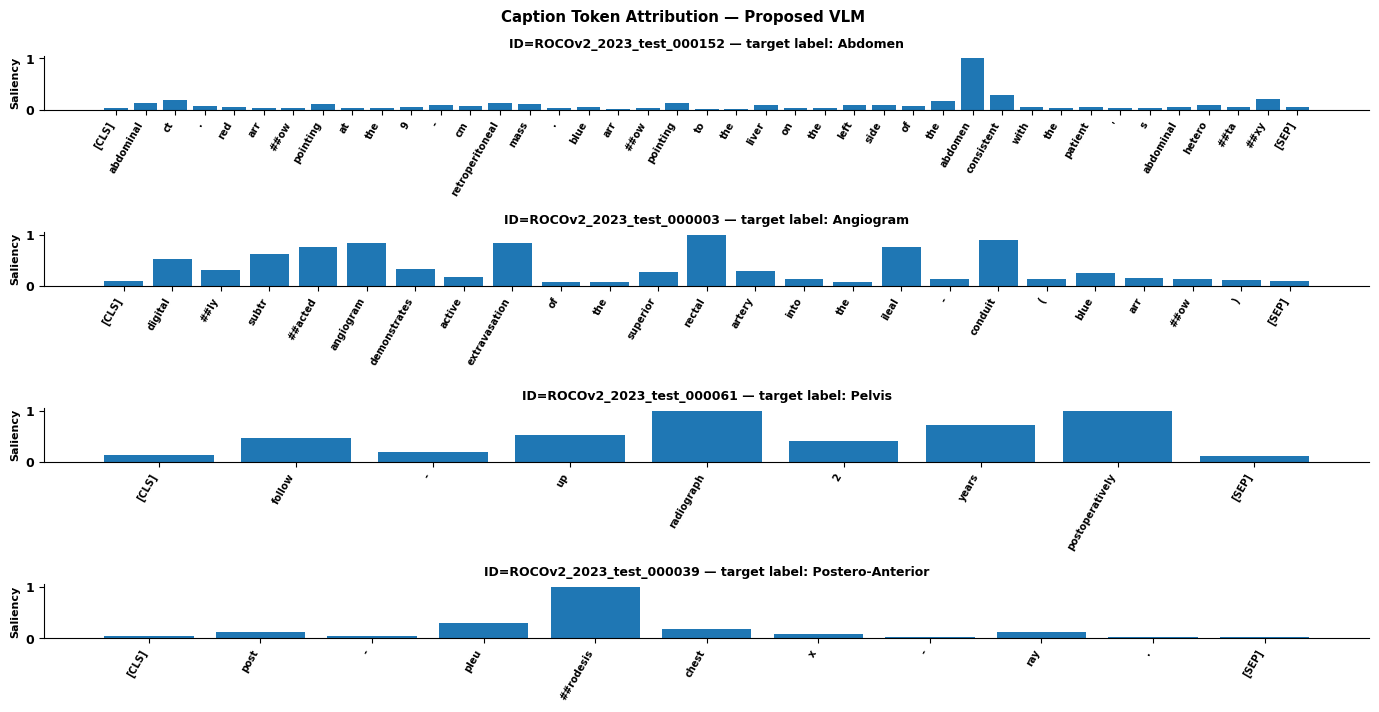

Saved: /content/drive/MyDrive/ROCOv2/Prepared/XAI/figures/caption_token_attribution.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/XAI/figures/caption_token_attribution_300dpi.png
Saved: /content/drive/MyDrive/ROCOv2/Prepared/XAI/xai_case_studies.csv


In [23]:
# ============================================================
# CELL 11 — CAPTION TOKEN ATTRIBUTION FIGURE
# ============================================================

n_cases_text = len(text_attribution_results)
fig, axes = plt.subplots(n_cases_text, 1, figsize=(14, 1.8 * n_cases_text))
if n_cases_text == 1:
    axes = [axes]

for ax, result in zip(axes, text_attribution_results):
    tokens = result["tokens"]
    saliency = result["saliency"]
    saliency_norm = saliency / (saliency.max() + 1e-8)

    display_tokens = [t for t in tokens if t not in ("[PAD]", "<pad>")]
    n_display = len(display_tokens)
    ax.bar(range(n_display), saliency_norm[:n_display], color="#1f77b4")
    ax.set_xticks(range(n_display))
    ax.set_xticklabels(display_tokens, rotation=60, ha="right", fontsize=7)
    ax.set_ylabel("Saliency", fontsize=8)
    ax.set_title(f"ID={result['ID']} — target label: {result['Label_Name']}", fontsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Caption Token Attribution — Proposed VLM", fontweight="bold")
fig.tight_layout()
fig.savefig(TEXT_ATTRIBUTION_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(TEXT_ATTRIBUTION_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", TEXT_ATTRIBUTION_FIGURE_PDF)
print("Saved:", TEXT_ATTRIBUTION_FIGURE_PNG)

case_studies_export = case_selection_df.copy()
safe_save_csv(CASE_STUDY_TABLE_PATH, case_studies_export)


## 11. Save configuration and reproducibility record

In [24]:
# ============================================================
# CELL 12 — SAVE CONFIG AND REPRODUCIBILITY.JSON
# ============================================================

xai_config = {
    "scope": ["densenet121", "biomedclip_zeroshot", "proposed_vlm"],
    "image_attribution_method": "Grad-CAM",
    "vit_target_layer_note": (
        "Last ViT transformer block's patch tokens, NOT literal attention-"
        "rollout — a deliberate substitution for cross-version robustness "
        "(see Cell 0 markdown)."
    ),
    "text_attribution_method": "Gradient-norm saliency per caption token (Proposed VLM only)",
    "n_case_studies": N_CASE_STUDIES,
    "min_confidence_for_case_selection": MIN_CONFIDENCE_FOR_CASE_SELECTION,
    "patch_grid_size": int(PATCH_GRID_SIZE),
    "label_columns": LABEL_COLUMNS, "label_names": LABEL_NAMES,
}
safe_save_json(XAI_CONFIG_PATH, xai_config)

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

reproducibility = {
    "notebook": "10_ROCOv2_XAI",
    "python_version": sys.version, "platform": platform.platform(),
    "pytorch_version": torch.__version__, "open_clip_version": package_version("open_clip"),
    "numpy_version": np.__version__, "pandas_version": pd.__version__,
    "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "random_seed": SEED,
    "source_checkpoints": {
        "densenet121": str(DENSENET_BEST_MODEL_PATH),
        "biomedclip_zeroshot": BIOMEDCLIP_CHECKPOINT + " (pretrained, untouched)",
        "proposed_vlm": str(VLM_BEST_MODEL_PATH),
    },
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/XAI/xai_config.json
Saved: /content/drive/MyDrive/ROCOv2/Prepared/XAI/reproducibility.json


In [ ]:
"""
TASK 5 — Quantitative explainability (faithfulness) validation.

STATUS: wired against 10_ROCOv2_XAI.ipynb's actual Cell 4/5/7/8/10 objects
(biomedclip_vlm, vlm_classifier_head, biomedclip_preprocess,
biomedclip_tokenizer, compute_grad_cam, compute_caption_token_attribution,
etc.), but NOT YET EXECUTED end-to-end with real data as of this version --
run it in Colab and confirm the output CSV before citing any faithfulness
number in the manuscript. Written outside the Colab environment (no GPU/
checkpoint locally), so treat the first real run as a validation pass, not
a guaranteed-correct result. See task5_explainability_findings.md for the
honest A-vs-B distinction this task requires (no ground-truth localization
annotations exist for ROCOv2 -- Part A is not applicable).

What this computes, once run with the real checkpoint:
  (B) Model-based explanation faithfulness -- NOT ground-truth localization
      (no expert segmentation/bbox annotations exist in ROCOv2 or this
      project; Part A of Task 5 is therefore N/A and must not be
      fabricated).

  Image (Grad-CAM) faithfulness, per case-study sample x predicted-positive label:
    - Deletion curve: progressively mask the top-k% of Grad-CAM-highlighted
      patches (most-salient first) with the dataset mean pixel value: 0, 10,
      ..., 100% of patches masked; record the model's predicted probability
      for that label at each step.
    - Insertion curve: mirror image -- start from a fully blurred/mean image
      and progressively reveal the top-k% most-salient patches.
    - Metrics: AUC of the deletion curve (lower = more faithful -- removing
      important regions should sharply drop confidence) and AUC of the
      insertion curve (higher = more faithful).
    - Comprehensiveness = P(original) - P(top-20%-patches-removed).
    - Sufficiency = P(top-20%-patches-only) - P(fully-masked-baseline).

  Caption (gradient-norm token attribution) faithfulness, same samples:
    - Token deletion sensitivity: remove the top-k highest-attribution
      tokens from the caption (k = 1..5), re-tokenize, re-run the model,
      record confidence drop.
    - Comprehensiveness/sufficiency, analogous to the image case, defined
      over token removal instead of patch masking.

Usage (Colab, with the real checkpoint mounted):
  1. Run Notebook 10 top to bottom first, in the same kernel, through at
     least Cell 10 (caption token attribution) -- this is what puts
     `biomedclip_vlm`, `vlm_classifier_head`, `biomedclip_preprocess`,
     `biomedclip_tokenizer`, `device`, `LABEL_NAMES`, `read_test_image_bytes`,
     `compute_grad_cam`, `vlm_vit_layer`, `PATCH_GRID_SIZE`,
     `compute_caption_token_attribution`, and `PREPARED_DIR` into the
     session's global namespace, which every function below relies on.
  2. Paste this whole file into a new cell and run it.
  3. Call `run_faithfulness_suite(cases_df=case_selection_df)` (reusing
     Notebook 10's own case-selection dataframe -- the same 4 cases already
     used for the qualitative figures, so the quantitative and qualitative
     evidence are about the same explanations). If `case_selection_df` isn't
     in scope, pass `xai_case_studies_path=...` instead.
  4. It saves `explainability_quantitative_results.csv` under
     `PREPARED_DIR/XAI/` in the schema below. Copy it into
     `Q1_Revision/outputs/task5_explainability/` afterwards.

  Wiring notes: the 5 adapter functions below (load_sample_image_tensor,
  get_gradcam_heatmap, get_token_attribution, predict_image_prob,
  predict_text_prob) are already wired to Notebook 10's Cell 4/5/7/8/10
  objects and functions as of this version. If your Notebook 10 code
  differs from what this was written against (e.g. different variable
  names, a different tokenizer wrapper), those 5 functions are the only
  places you should need to adjust.

Output schema (one row per sample x label x method x metric):
  ID, Label_Name, Method ("gradcam" | "token_attribution"),
  Metric ("deletion_auc" | "insertion_auc" | "comprehensiveness" | "sufficiency"),
  Value, Original_Prob, N_Steps
"""
import io
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image

# This file is meant to be pasted into the SAME Colab session as Notebook 10,
# after it has run top to bottom -- it reuses these objects Notebook 10
# already created in the global namespace (not reimported/redefined here):
#   biomedclip_vlm, vlm_classifier_head, biomedclip_preprocess,
#   biomedclip_tokenizer, device, LABEL_NAMES, read_test_image_bytes,
#   compute_grad_cam, get_vit_target_layer, vlm_vit_layer, PATCH_GRID_SIZE,
#   compute_caption_token_attribution


def deletion_insertion_curves(image_tensor, cam_heatmap, patch_grid_size, predict_fn, mean_value=0.0, n_steps=11):
    """
    image_tensor: (C,H,W) normalized tensor for the sample.
    cam_heatmap: (patch_grid_size, patch_grid_size) Grad-CAM saliency, already
        the same one shown in Notebook 10's qualitative figure for this
        sample/label -- reuse it, do not recompute independently.
    predict_fn: callable(masked_image_tensor) -> float probability for the
        target label (wraps _predict_prob with the sample's fixed caption).
    Returns: dict(deletion_probs, insertion_probs, fractions)
    """
    c, h, w = image_tensor.shape
    ph, pw = h // patch_grid_size, w // patch_grid_size
    flat_scores = cam_heatmap.flatten()
    order = np.argsort(-flat_scores)  # most salient first
    n_patches = len(order)
    fractions = np.linspace(0, 1, n_steps)

    deletion_probs, insertion_probs = [], []
    for frac in fractions:
        k = int(round(frac * n_patches))
        deletion_img = image_tensor.clone()
        insertion_img = torch.full_like(image_tensor, mean_value)
        for idx in order[:k]:
            r, col = divmod(idx, patch_grid_size)
            deletion_img[:, r * ph:(r + 1) * ph, col * pw:(col + 1) * pw] = mean_value
            insertion_img[:, r * ph:(r + 1) * ph, col * pw:(col + 1) * pw] = image_tensor[:, r * ph:(r + 1) * ph, col * pw:(col + 1) * pw]
        deletion_probs.append(predict_fn(deletion_img))
        insertion_probs.append(predict_fn(insertion_img))

    return {"fractions": fractions.tolist(), "deletion_probs": deletion_probs, "insertion_probs": insertion_probs}


def token_deletion_curve(tokens, token_attribution_scores, predict_fn_text, max_k=5):
    """
    tokens: list[str] caption tokens for this sample (already tokenized the
        same way Notebook 10's gradient-norm attribution used).
    token_attribution_scores: same-length array of |gradient|-norm scores.
    predict_fn_text: callable(list[str]) -> float probability for the target
        label, re-encoding the modified caption through the text tower.
    """
    order = np.argsort(-np.asarray(token_attribution_scores))
    probs = [predict_fn_text(tokens)]  # k=0, original
    removed = set()
    for k in range(1, min(max_k, len(tokens)) + 1):
        removed.add(int(order[k - 1]))
        remaining = [t for i, t in enumerate(tokens) if i not in removed]
        probs.append(predict_fn_text(remaining))
    return probs


def curve_auc(fractions, probs):
    return float(np.trapz(probs, fractions))


# =============================================================================
# WIRING LAYER -- fill in these 5 functions using Notebook 10's own objects.
# Each is a thin adapter: call what Notebook 10 already computes, reshape to
# the type/shape described in the docstring. Do not reimplement Grad-CAM or
# gradient-norm attribution here.
# =============================================================================

def _load_pil_image(image_member):
    raw_bytes = read_test_image_bytes(image_member)  # Notebook 10, Cell 5
    with Image.open(io.BytesIO(raw_bytes)) as img:
        return img.convert("RGB")


def load_sample_image_tensor(image_member):
    """Returns a (C,H,W) CPU tensor via BiomedCLIP's own preprocessing transform."""
    pil_image = _load_pil_image(image_member)
    return biomedclip_preprocess(pil_image)


def get_gradcam_heatmap(image_member, label_idx, caption):
    """
    Reuses Notebook 10's compute_grad_cam() + vlm_vit_layer/PATCH_GRID_SIZE
    (Cell 7/8) with the Proposed VLM, exactly as in its own Grad-CAM cell,
    but for an arbitrary (image, label) pair instead of only the 4
    qualitative case studies. Returns the raw (PATCH_GRID_SIZE,
    PATCH_GRID_SIZE) saliency map (pre-upsampling, pre-colormap).
    """
    pil_image = _load_pil_image(image_member)
    vlm_input = biomedclip_preprocess(pil_image).unsqueeze(0).to(device).requires_grad_(True)
    with torch.no_grad():
        text_tokens = biomedclip_tokenizer([str(caption)]).to(device)
        text_embed_fixed = F.normalize(biomedclip_vlm.encode_text(text_tokens), dim=-1)

    def vlm_forward():
        img_embed = F.normalize(biomedclip_vlm.encode_image(vlm_input), dim=-1)
        fused = torch.cat([img_embed, text_embed_fixed], dim=-1)
        return vlm_classifier_head(fused)

    return compute_grad_cam(vlm_forward, vlm_vit_layer, label_idx, is_vit=True, patch_grid_size=PATCH_GRID_SIZE)


def get_token_attribution(caption, label_idx, image_member):
    """Thin wrapper around Notebook 10's own compute_caption_token_attribution (Cell 10)."""
    pil_image = _load_pil_image(image_member)
    tokens, saliency = compute_caption_token_attribution(pil_image, str(caption), label_idx)
    return tokens, saliency


@torch.no_grad()
def predict_image_prob(image_tensor, caption, label_idx):
    """Forward pass: given (possibly perturbed) image_tensor + the ORIGINAL caption -> P(label_idx)."""
    img_input = image_tensor.unsqueeze(0).to(device)
    text_tokens = biomedclip_tokenizer([str(caption)]).to(device)
    img_embed = F.normalize(biomedclip_vlm.encode_image(img_input), dim=-1)
    text_embed = F.normalize(biomedclip_vlm.encode_text(text_tokens), dim=-1)
    fused = torch.cat([img_embed, text_embed], dim=-1)
    logits = vlm_classifier_head(fused)
    return torch.sigmoid(logits)[0, label_idx].item()


def _wordpiece_tokens_to_text(tokens):
    """
    Reassembles PubMedBERT WordPiece tokens (e.g. 'chest', '##graph') back
    into a plain string, dropping special tokens ([CLS]/[SEP]/[PAD]).
    Standard practice for token-deletion faithfulness checks: the
    reconstructed string is re-tokenized fresh by the model's own
    tokenizer rather than hand-building an input_ids tensor, so padding/
    truncation/special-token handling stays exactly as the model expects.
    """
    special = {"[CLS]", "[SEP]", "[PAD]"}
    pieces = []
    for t in tokens:
        if t in special:
            continue
        if t.startswith("##") and pieces:
            pieces[-1] = pieces[-1] + t[2:]
        else:
            pieces.append(t)
    return " ".join(pieces)


@torch.no_grad()
def predict_text_prob(image_tensor, remaining_tokens, label_idx):
    """Forward pass: the ORIGINAL image + a caption rebuilt from remaining_tokens -> P(label_idx)."""
    reconstructed_caption = _wordpiece_tokens_to_text(remaining_tokens)
    img_input = image_tensor.unsqueeze(0).to(device)
    text_tokens = biomedclip_tokenizer([reconstructed_caption]).to(device)
    img_embed = F.normalize(biomedclip_vlm.encode_image(img_input), dim=-1)
    text_embed = F.normalize(biomedclip_vlm.encode_text(text_tokens), dim=-1)
    fused = torch.cat([img_embed, text_embed], dim=-1)
    logits = vlm_classifier_head(fused)
    return torch.sigmoid(logits)[0, label_idx].item()


# =============================================================================
# ORCHESTRATOR -- should not need editing once the 5 functions above are wired.
# =============================================================================

def run_faithfulness_suite(
    cases_df=None,
    xai_case_studies_path=None,
    output_path=None,
    patch_grid_size=None,
    n_deletion_insertion_steps=11,
    max_tokens_removed=5,
):
    """
    Runs the Grad-CAM and token-attribution faithfulness suites over a set
    of (sample, label) cases and writes the required output CSV.

    Pass EITHER:
      - cases_df: Notebook 10's own `case_selection_df` (already in memory
        after running its cells) -- the simplest, most robust option, since
        it avoids re-deriving the Drive path.
      - xai_case_studies_path: a path to the saved xai_case_studies.csv, if
        cases_df isn't available. Columns required: ID, Label_Name, Prob,
        Image_Member, Caption.

    output_path defaults to PREPARED_DIR / "XAI" / "explainability_quantitative_results.csv"
    if PREPARED_DIR exists in the calling namespace (it does, from Notebook 10, Cell 1);
    otherwise falls back to a relative path.
    patch_grid_size defaults to Notebook 10's own PATCH_GRID_SIZE global if not passed.
    """
    if cases_df is not None:
        cases = cases_df
    elif xai_case_studies_path is not None:
        cases = pd.read_csv(xai_case_studies_path)
    else:
        cases = pd.read_csv(PREPARED_DIR / "XAI" / "xai_case_studies.csv")  # noqa: F821 (Notebook 10 global)

    if output_path is None:
        output_path = PREPARED_DIR / "XAI" / "explainability_quantitative_results.csv"  # noqa: F821
    if patch_grid_size is None:
        patch_grid_size = PATCH_GRID_SIZE  # noqa: F821 (Notebook 10 global, Cell 8)

    rows = []

    for _, case in cases.iterrows():
        sample_id, label_name = case["ID"], case["Label_Name"]
        image_member, caption, original_prob = case["Image_Member"], case["Caption"], case["Prob"]
        label_idx = LABEL_NAMES.index(label_name)  # Notebook 10's own LABEL_NAMES list

        image_tensor = load_sample_image_tensor(image_member)

        # --- Grad-CAM faithfulness ---
        cam = get_gradcam_heatmap(image_member, label_idx, caption)
        curves = deletion_insertion_curves(
            image_tensor, cam, patch_grid_size,
            predict_fn=lambda img: predict_image_prob(img, caption, label_idx),
            n_steps=n_deletion_insertion_steps,
        )
        fractions = curves["fractions"]
        deletion_auc = curve_auc(fractions, curves["deletion_probs"])
        insertion_auc = curve_auc(fractions, curves["insertion_probs"])
        # comprehensiveness/sufficiency at the ~20% mark (nearest available step)
        idx20 = int(np.argmin(np.abs(np.array(fractions) - 0.20)))
        comprehensiveness = curves["deletion_probs"][0] - curves["deletion_probs"][idx20]
        sufficiency = curves["insertion_probs"][idx20] - curves["insertion_probs"][0]
        for metric, value in [("deletion_auc", deletion_auc), ("insertion_auc", insertion_auc),
                               ("comprehensiveness", comprehensiveness), ("sufficiency", sufficiency)]:
            rows.append({"ID": sample_id, "Label_Name": label_name, "Method": "gradcam",
                         "Metric": metric, "Value": value, "Original_Prob": original_prob,
                         "N_Steps": n_deletion_insertion_steps})

        # --- Token attribution faithfulness ---
        tokens, scores = get_token_attribution(caption, label_idx, image_member)
        probs = token_deletion_curve(
            tokens, scores,
            predict_fn_text=lambda toks: predict_text_prob(image_tensor, toks, label_idx),
            max_k=max_tokens_removed,
        )
        k_fractions = np.linspace(0, 1, len(probs))
        deletion_auc_txt = curve_auc(k_fractions, probs)
        rows.append({"ID": sample_id, "Label_Name": label_name, "Method": "token_attribution",
                     "Metric": "deletion_auc", "Value": deletion_auc_txt, "Original_Prob": original_prob,
                     "N_Steps": len(probs)})
        rows.append({"ID": sample_id, "Label_Name": label_name, "Method": "token_attribution",
                     "Metric": "comprehensiveness", "Value": probs[0] - probs[-1],
                     "Original_Prob": original_prob, "N_Steps": len(probs)})

    result_df = pd.DataFrame(rows)
    Path(output_path).parent.mkdir(parents=True, exist_ok=True)
    result_df.to_csv(output_path, index=False)
    print(f"Saved {len(result_df)} rows to {output_path}")
    return result_df


print(
    "task5_faithfulness_COLAB_ONLY.py loaded and wired to Notebook 10's objects "
    "(biomedclip_vlm, vlm_classifier_head, biomedclip_preprocess, biomedclip_tokenizer, "
    "compute_grad_cam, compute_caption_token_attribution, etc.).\n"
    "If NameErrors appear below, Notebook 10 wasn't run far enough in this session first "
    "(needs through Cell 10) -- run it top to bottom, then re-paste this file.\n"
    "Otherwise, call: run_faithfulness_suite(cases_df=case_selection_df)"
)


In [ ]:
run_faithfulness_suite(cases_df=faithfulness_case_selection_df,
                        output_path=XAI_DIR / "explainability_quantitative_results_expanded.csv")


## 12. Artifact manifest and final report

In [26]:
ALLOW_OVERWRITE=True

In [27]:
# ============================================================
# CELL 13 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    CASE_STUDY_TABLE_PATH, GRADCAM_FIGURE_PDF, GRADCAM_FIGURE_PNG,
    TEXT_ATTRIBUTION_FIGURE_PDF, TEXT_ATTRIBUTION_FIGURE_PNG,
    XAI_CONFIG_PATH, REPRODUCIBILITY_PATH,
]
manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"
safe_save_json(MANIFEST_PATH, {"artifacts": manifest, "status": notebook_status})

print("\n" + "=" * 60)
print("ROCOv2 XAI")
print("FINAL REPORT")
print("=" * 60)
print(f'''
Models:
DenseNet121 (05), BiomedCLIP zero-shot (06), Proposed VLM (07) — all read-only

Image attribution method:
Grad-CAM (CNN: last conv feature map | ViT: last transformer block's patch tokens)

Text attribution method:
Gradient-norm caption-token saliency (Proposed VLM only)

Case studies:
{N_CASE_STUDIES} (confidence > {MIN_CONFIDENCE_FOR_CASE_SELECTION}, distinct labels, fixed seed)

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

XAI attribution implemented:
YES (Grad-CAM x3 models, caption attribution x1 model)

Previous notebooks modified:
NO

Any model re-trained:
NO — all three checkpoints loaded read-only

Ready for Trust Score notebook:
{"YES" if not manifest_missing else "NO"}
''')
print("=" * 60)

if notebook_status != "COMPLETE":
    print("\nNOTEBOOK 10 STATUS: NOT READY — see missing artifacts above. "
          "Do not treat this run as complete.")
else:
    print("\nSTOP — Notebook 10 (XAI) is complete.")
    print("Not implemented here (by design): Trust Score.")
    print("Next notebook: 11_ROCOv2_Trust_Score.ipynb")


,Artifact,Path,Exists,Size_KB
0,xai_case_studies.csv,/content/drive/MyDrive/ROCOv2/Prepared/XAI/xai...,True,0.70
1,gradcam_comparison.pdf,/content/drive/MyDrive/ROCOv2/Prepared/XAI/fig...,True,1905.88
2,gradcam_comparison_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/XAI/fig...,True,1668.99
3,caption_token_attribution.pdf,/content/drive/MyDrive/ROCOv2/Prepared/XAI/fig...,True,24.20
4,caption_token_attribution_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/XAI/fig...,True,441.52
5,xai_config.json,/content/drive/MyDrive/ROCOv2/Prepared/XAI/xai...,True,1.32
6,reproducibility.json,/content/drive/MyDrive/ROCOv2/Prepared/XAI/rep...,True,0.74


Saved: /content/drive/MyDrive/ROCOv2/Prepared/XAI/artifact_manifest.json

ROCOv2 XAI
FINAL REPORT

Models:
DenseNet121 (05), BiomedCLIP zero-shot (06), Proposed VLM (07) — all read-only

Image attribution method:
Grad-CAM (CNN: last conv feature map | ViT: last transformer block's patch tokens)

Text attribution method:
Gradient-norm caption-token saliency (Proposed VLM only)

Case studies:
4 (confidence > 0.7, distinct labels, fixed seed)

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

XAI attribution implemented:
YES (Grad-CAM x3 models, caption attribution x1 model)

Previous notebooks modified:
NO

Any model re-trained:
NO — all three checkpoints loaded read-only

Ready for Trust Score notebook:
YES


STOP — Notebook 10 (XAI) is complete.
Not implemented here (by design): Trust Score.
Next notebook: 11_ROCOv2_Trust_Score.ipynb
